# Imports

In [4]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize, BoundaryNorm

# Simulation Functions

In [5]:
# Function that adds exposed inidivuals to a random position
def random_position(x):
    # Obtaining random position
    i = np.random.randint(0,len(x[0,:,:]))
    j = np.random.randint(0,len(x[0,:,:]))

    # Adding exposed individuals to random position
    if x[0,i,j] != 2:
        x[0,i,j] = 2
        return x
    else:
        random_position(x) # Calling teh same function so no overlaps occur


# Function that Initialises the grid
def initialise_grid(ksize, initial_e):
    x = np.ones((2, size, size))

    # Adds specified number (initial_e) of exposed inidividuals to the grid randomly
    for num in range(initial_e):
        x = random_position(x)
    return x

def generate_directions(d):
    directions = []
    for i in range(-d, d + 1):
        for j in range(-d, d + 1):
            if i == 0 and j == 0:
                continue  # Skip the zero vector (current cell)
            directions.append((i, j))
    return directions

# Function that returns the number of infectious neighbour species present
def num_infectious_neighbours(x, i, j, t_i, t_q, t_r, d):
    # All possible directions for neighbours
    directions = generate_directions(d)
    count = 0

    # Loops through the directions array
    for d in range(len(directions)):
        # Reassigned to save space
        d_i = directions[d][0]
        d_j = directions[d][1]

        # Directions are added to the cell observed to identify all possible neighbours
        d_i += i
        d_j += j

        # Assures that neighbours that go out of the boundaries are not counted
        if (-1 < d_i < len(x)) and (-1 < d_j < len(x)) and ((x[d_i][d_j] == 2) or (x[d_i][d_j] == 3)):
            count += 1
    return count


# Function that applies state transitions and returns the resulting array
def advance(x, n, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d):
    result = np.ones((2, size, size))

    # loop over all cells in the grid
    for i in range(0,n):
        for j in range(0,n):
            # Determines the number of infectious neighbours of cell i,j
            num_infectious = num_infectious_neighbours(x[0,:,:], i, j, t_i, t_q, t_r, d)

            # State transition conditions and delay periods

            # Individuals removed of the virus stay removed
            if x[0,i,j] == 5:
                result[0,i,j] = 5

            # Conditions for susceptible indviduals to become exposed
            elif x[0,i,j] == 1:
                if np.random.rand() <= p_e and num_infectious > 0:
                    result[0,i,j] = 2
                else:
                    result[0,i,j] = x[0,i,j] # Remain in current state if conditions not met

            # Conditions for exposed individuals to become infected
            elif x[0,i,j] == 2:
                if x[1,i,j] >= (t_i) and np.random.rand() <= p_i:
                    result[0,i,j] = 3
                    result[1,i,j] = 1 # Reset timer
                else:
                    result[0,i,j] = x[0,i,j] # Remain in current state if conditions not met
                    result[1,i,j] = x[1,i,j] + 1 # Increment timer

            # Conditionss for infected individuals with symptoms to become quarantined or removed of the virus
            elif x[0,i,j] == 3:
                if x[1,i,j] == (t_q) and np.random.rand() <= p_q:
                    result[0,i,j] = 4
                    result[1,i,j] = 1 # Reset timer
                elif x[1,i,j] >= (t_q + t_r) and np.random.rand() <= p_r:
                    result[0,i,j] = 5
                    result[1,i,j] = 1 # Reset timer
                else:
                    result[0,i,j] = x[0,i,j] # Remain in current state if conditions not met
                    result[1,i,j] = x[1,i,j] + 1 # Increment timer

            # Conditions for quarantined individuals to become removed of the virus
            elif x[0,i,j] == 4:
                if x[1,i,j] >= (t_r) and np.random.rand() <= p_r:
                    result[0,i,j] = 5
                    result[1,i,j] = 1 # Reset timer
                else:
                    result[0,i,j] = x[0,i,j] # Remain in current state if conditions not met
                    result[1,i,j] = x[1,i,j] + 1 # Increment timer
    return result

# Simulation Grid Visualisation Functions

In [16]:
# Function that creates a legend for simulation
def legend(axs):
    # Labels and corresponding colours for each state
    state_labels = ['Empty', 'Susceptible', 'Exposed', 'Infected', 'Quarantined', 'Recovered']
    state_colours = ['white', 'yellow', 'orange', 'red', 'blue', 'green']

    handles = []

    for label, color in zip(state_labels, state_colours):
        handles.append(plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=color, markersize=10, label=label))

    axs[0, 9].legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize = 25)
    axs[0, 9].axis('off')


# Function that defines the colour map
def cmap():
    # Colours and corresponding boundaries for each state 
    state_colours = ['white','yellow', 'orange', 'red', 'blue', 'green']
    boundaries = [0, 1, 2, 3, 4, 5, 6]

    custom_cmap = ListedColormap(state_colours)
    norm = BoundaryNorm(boundaries, len(state_colours))

    return custom_cmap, norm


# Function that plots the grid for simulation
def sim_plot(x, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d):
    # Setting up colour map
    custom_cmap, norm = cmap()

    # Number of rows and columns for the figure
    num_rows = int(days/ 10)
    num_cols = 10

    # Setting up the figure
    fig, axs = plt.subplots(num_rows, num_cols, figsize=(50, int(days/2)))

    # Looping through each subplot in the figure
    for i in range(num_rows):
        for j in range(num_cols):
            # Plotting the grid
            axs[i, j].imshow(x[0,:,:], cmap=custom_cmap, norm=norm)

            # Advances the grid
            x = advance(x, size, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d)

            # Setting the title for the subplot
            if i == 0 and j == 0:
                axs[0, 0].set_title("Initial State", fontsize = 25)
            else:
                axs[i, j].set_title(f"Iteration {(i * num_cols) + j}", fontsize = 25)

            axs[i, j].axis('off')

        # Adds the legend to the fifth subplot
        legend(axs)

    plt.tight_layout()

# Analysis Functions

In [17]:
# Variable class system
class VariableWrapper:
    def __init__(self, value, name):
        self.value = value
        self.name = name


# Function that obtains the number of individuals in each state
def count_states(x):
    count = np.zeros(6)

    count[0] = np.count_nonzero(x == 0) # Counting cells in empty state
    count[1] = np.count_nonzero(x == 1) # Counting cells in susceptible state
    count[2] = np.count_nonzero(x == 2) # Counting cells in exposed state
    count[3] = np.count_nonzero(x == 3) # Counting cells in infected state
    count[4] = np.count_nonzero(x == 4) # Counting cells in quarantined state
    count[5] = np.count_nonzero(x == 5) # Counting cells in removed state

    return count


# Function that runs through the simulation and collects the number of individuals in each state
def states_pop(x, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d):
    # Initialising arrays
    pop = []
    num_s = []
    num_e = []
    num_i = []
    num_q = []
    num_r = []

    # Appending initial counts
    pop.append(count_states(x[0,:,:]))

    # Looping through iterations
    for j in range(days):
        # Advancing the grid
        x = advance(x, size, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d)

        # Appending counts for the iteration
        pop.append(count_states(x[0,:,:]))

    # Looping through iterations
    for k in range((days + 1)):
        # Appends number of individuals in a state for all iterations
        num_s.append(pop[k][1])
        num_e.append(pop[k][2])
        num_i.append(pop[k][3])
        num_q.append(pop[k][4])
        num_r.append(pop[k][5])

    return num_s, num_e, num_i, num_q, num_r


# Function that plots the number of individuals over time for different values of a parameter
def plot_states(x, p, inc, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d):
    N = np.full((days + 1), (size * size)) # Total population

    # Setting up the figure
    fig, axs = plt.subplots(3, 2, figsize=(20, 10))

    # Looping through increments
    for i in range(5):
        if p.name == 'p_e':
            p_e = p.value
        elif p.name == 'p_i':
            p_i = p.value
        elif p.name == 'p_q':
            p_q = p.value
        elif p.name == 'p_r':
            p_r = p.value
        elif p.name == 't_q':
            t_q = p.value
        elif p.name == 'd':
            d = p.value

        # Collecting number of each state
        num_s, num_e, num_i, num_q, num_r = states_pop(x, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d)

        # PLotting graphs in corresponding subplot
        for a in range(3):
            for b in range(2):
                if a == 2 and b == 1:
                    break
                elif a == 0 and b == 0:
                    axs[a,b].plot(range(days+1), num_s/N, label=f'{p.name} = {round(p.value, 3)}', linewidth = 2)
                elif a == 0 and b == 1:
                    axs[a,b].plot(range(days+1), num_e/N, label=f'{p.name} = {round(p.value, 3)}', linewidth = 2)
                elif a == 1 and b == 0:
                    axs[a,b].plot(range(days+1), num_i/N, label=f'{p.name} = {round(p.value, 3)}', linewidth = 2)
                elif a == 1 and b == 1:
                    axs[a,b].plot(range(days+1), num_q/N, label=f'{p.name} = {round(p.value, 3)}', linewidth = 2)
                elif a == 2 and b == 0:
                    axs[a,b].plot(range(days+1), num_r/N, label=f'{p.name} = {round(p.value, 3)}', linewidth = 2)

        # Incrementing new value to plot in next loop
        p.value = p.value + inc[i]

    # Setting title, labels and legend for each subplot
    for a in range(3):
        for b in range(2):
            if a == 2 and b == 1:
                break
            elif a == 0 and b == 0:
                axs[a,b].set_title(f'Fraction of susceptible individuals over time for different values of {p.name}', fontsize = 14)
            elif a == 0 and b == 1:
                axs[a,b].set_title(f'Fraction of exposed individuals over time for different values of {p.name}', fontsize = 14)
            elif a == 1 and b == 0:
                axs[a,b].set_title(f'Fraction of infected individuals over time for different values of {p.name}', fontsize = 14)
            elif a == 1 and b == 1:
                axs[a,b].set_title(f'Fraction of quarantined individuals over time for different values of {p.name}', fontsize = 14)
            elif a == 2 and b == 0:
                axs[a,b].set_title(f'Fraction of individuals removed of the virus over time for different values of {p.name}', fontsize = 14)

            axs[a,b].set_xlabel('Days', fontsize = 14)
            axs[a,b].set_ylabel('Fraction of Population', fontsize = 14)
            axs[a,b].legend()
            axs[a,b].grid(True)
            axs[2,1].set_visible(False)

    plt.tight_layout()
    plt.show()

# Initial Simulation

In [19]:
# Default probabilities, time delays and variables
initial_e = 5

size = 100 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Default probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to become infected
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for exposed indviduals to become infected
t_q = 5 # Default time delay for infected indviduals to become quarantined
t_r = 5 # Default time delay for indviduals to become removed of the virus

d = 1 # Default value for population density

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
sim_plot(grid, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d)

# Main Analysis



<function matplotlib.pyplot.show(close=None, block=None)>

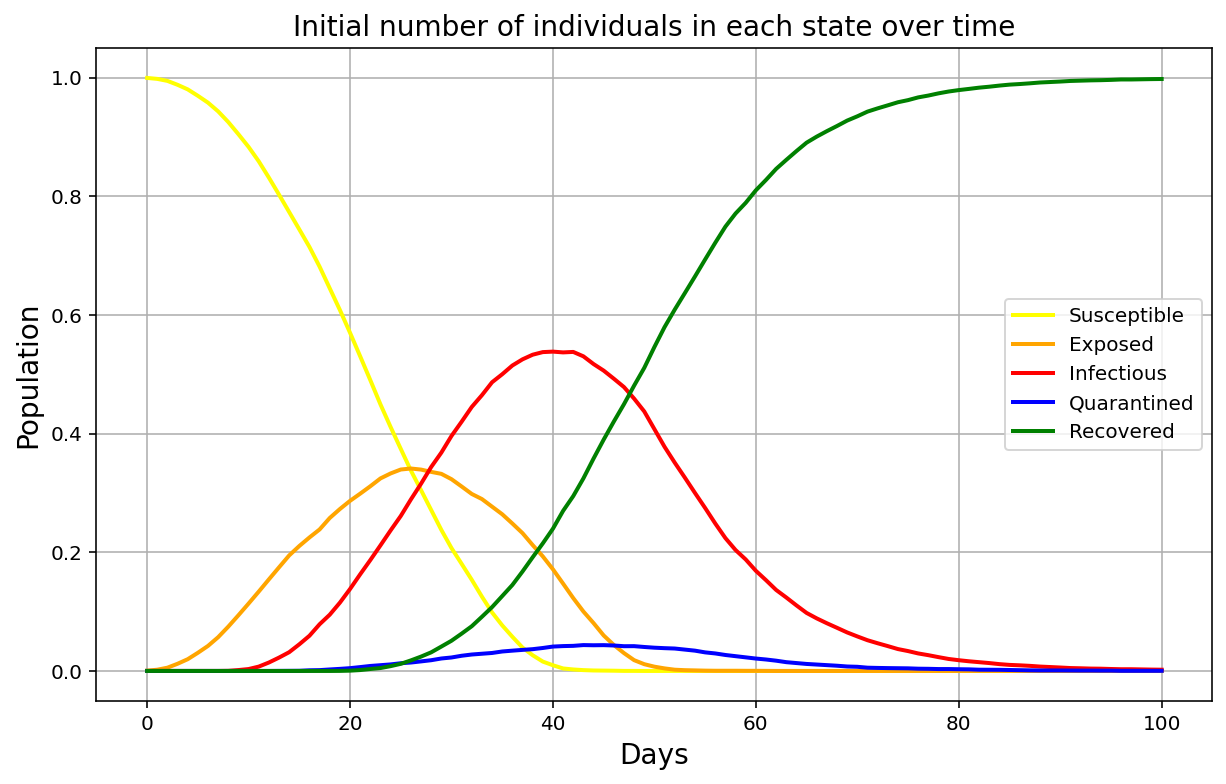

In [20]:
# Plot state counts over time
N = np.full((days + 1), (size * size)) # Total population

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Collecting number of each state
num_s, num_e, num_i, num_q, num_r = states_pop(grid, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d)

# Plotting
plt.figure(figsize = (10, 6))

plt.plot(range(days+1), num_s/N, label='Susceptible', color='yellow', linewidth = 2)
plt.plot(range(days+1), num_e/N, label='Exposed', color='orange', linewidth = 2)
plt.plot(range(days+1), num_i/N, label='Infectious', color='red', linewidth = 2)
plt.plot(range(days+1), num_q/N, label='Quarantined', color='blue', linewidth = 2)
plt.plot(range(days+1), num_r/N, label='Recovered', color='green', linewidth = 2)

plt.xlabel('Days', fontsize = 14)
plt.ylabel('Population', fontsize = 14)
plt.title('Initial number of individuals in each state over time', fontsize = 14)
plt.legend()
plt.grid(True)

plt.show

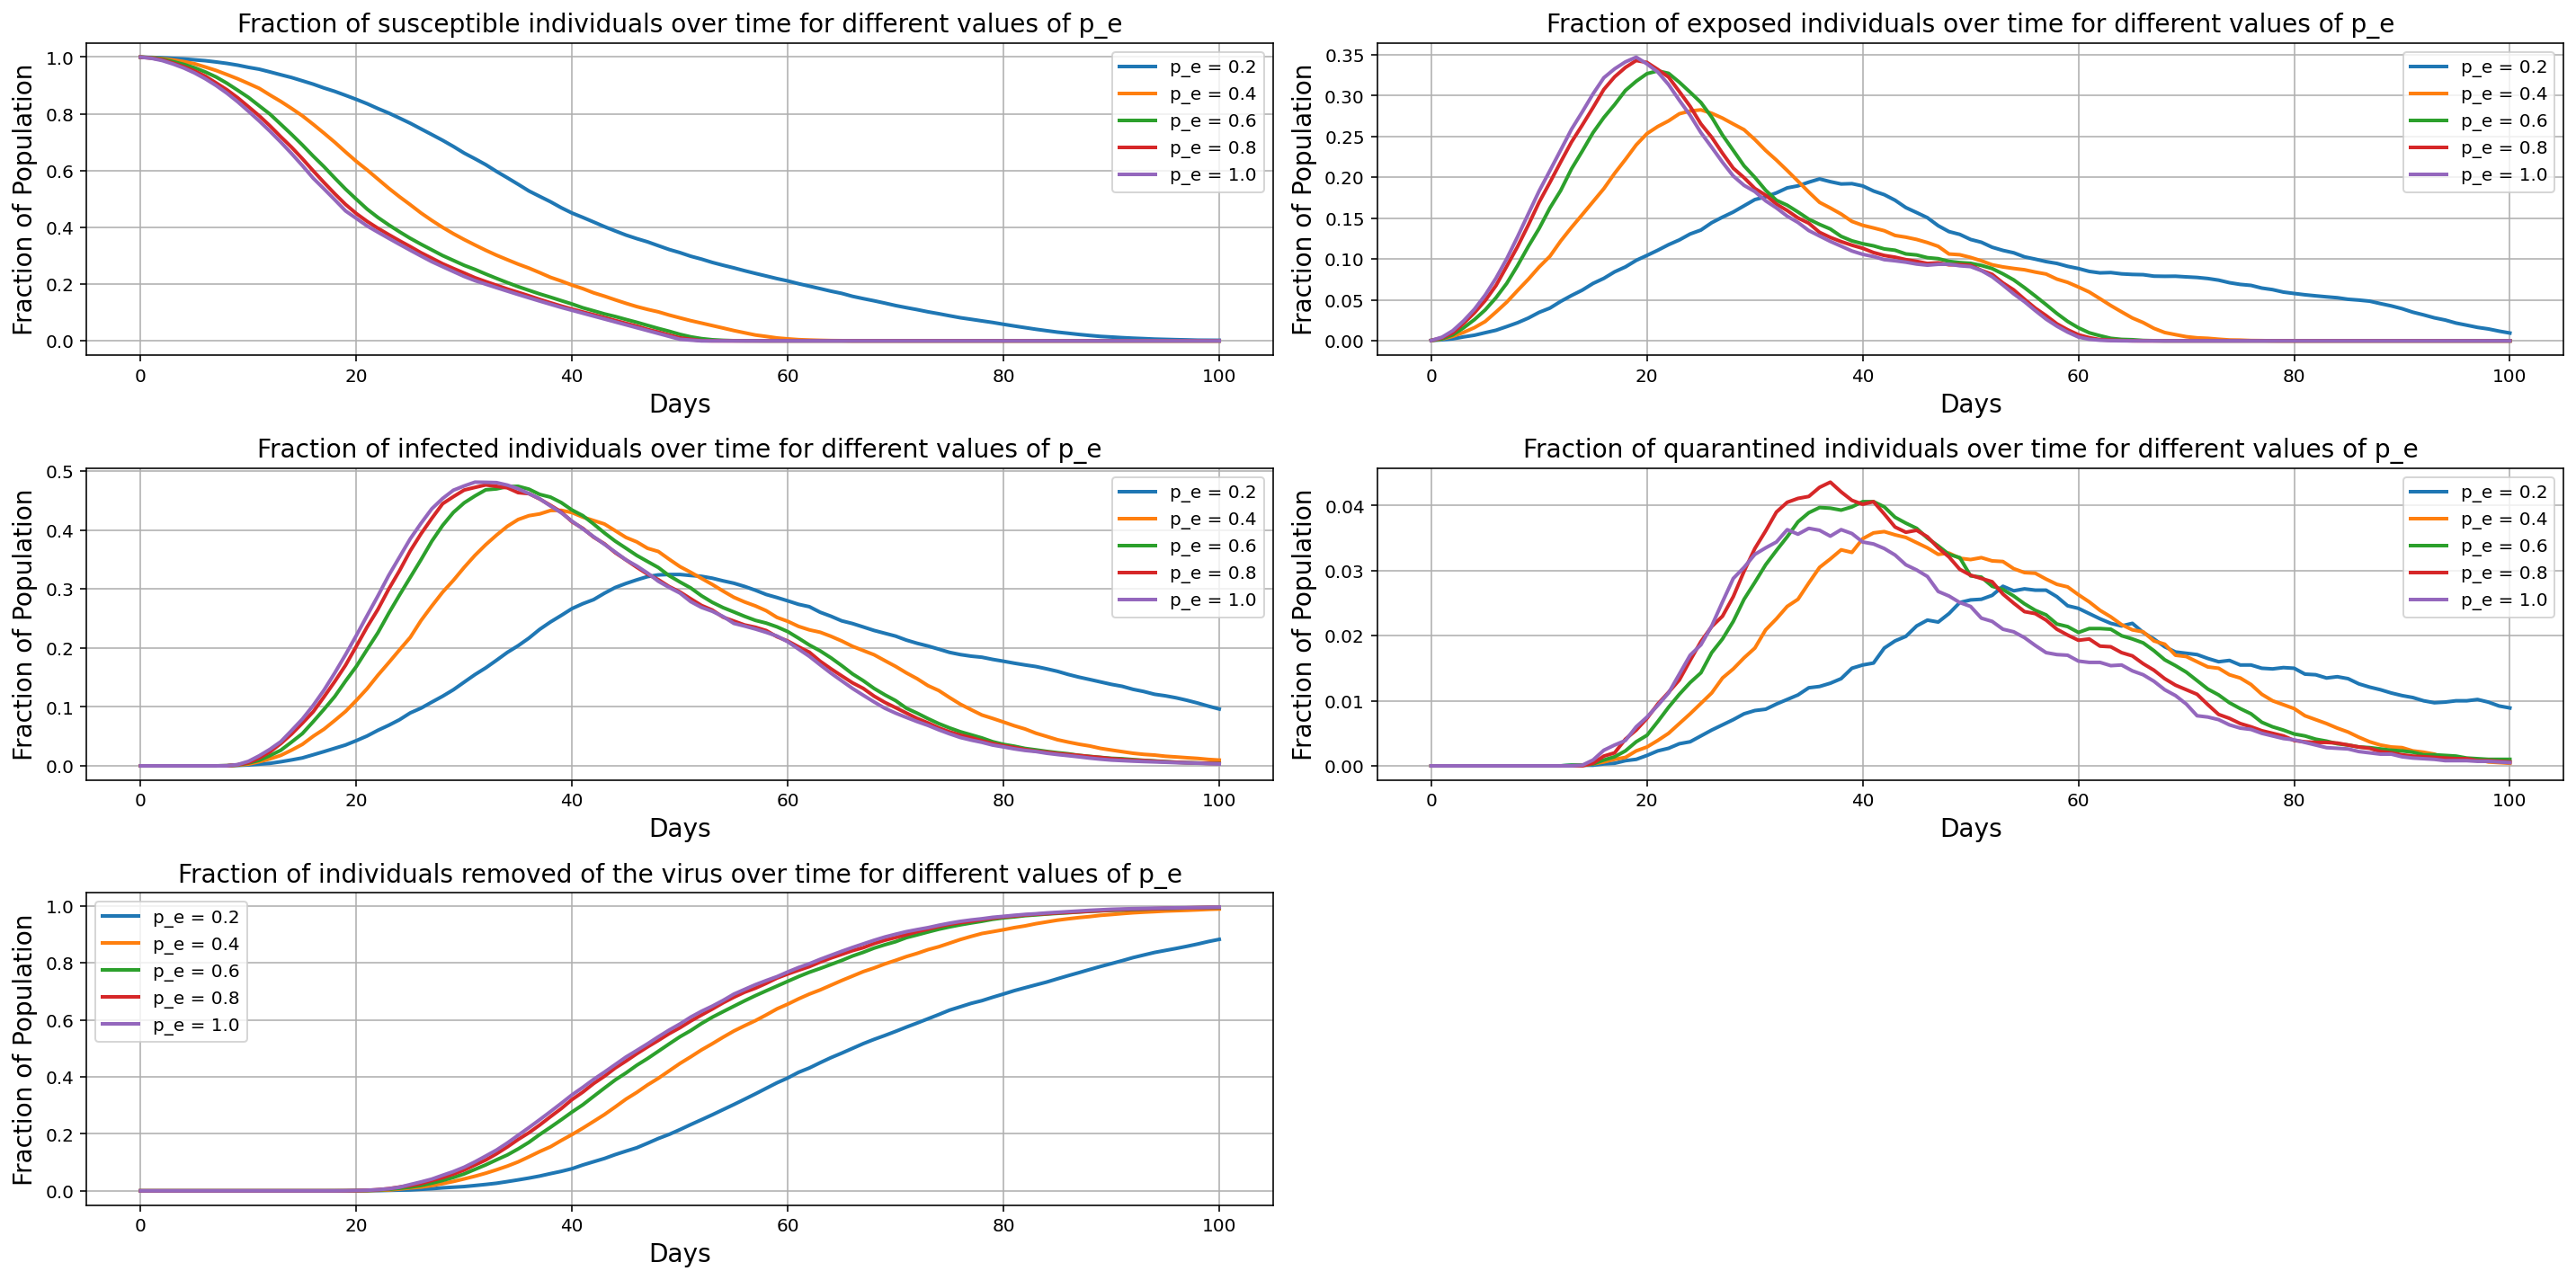

In [21]:
# Number of individuals over time for different values of p_e
initial_e = 5 # Initial number of exposed individuals

size = 100 # Size of grid
days = 100 # Days of simulation

p_e = VariableWrapper(0.2, 'p_e') # Initial probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to show symptoms after incubation period
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = 5 # Default time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = 1 # Default value for population density

inc = np.array([0.2, 0.2, 0.2, 0.2, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

#Plotting
plot_states(grid, p_e, inc, size, days, p_e.value, p_i, p_q, p_r, t_i, t_q, t_r, d)

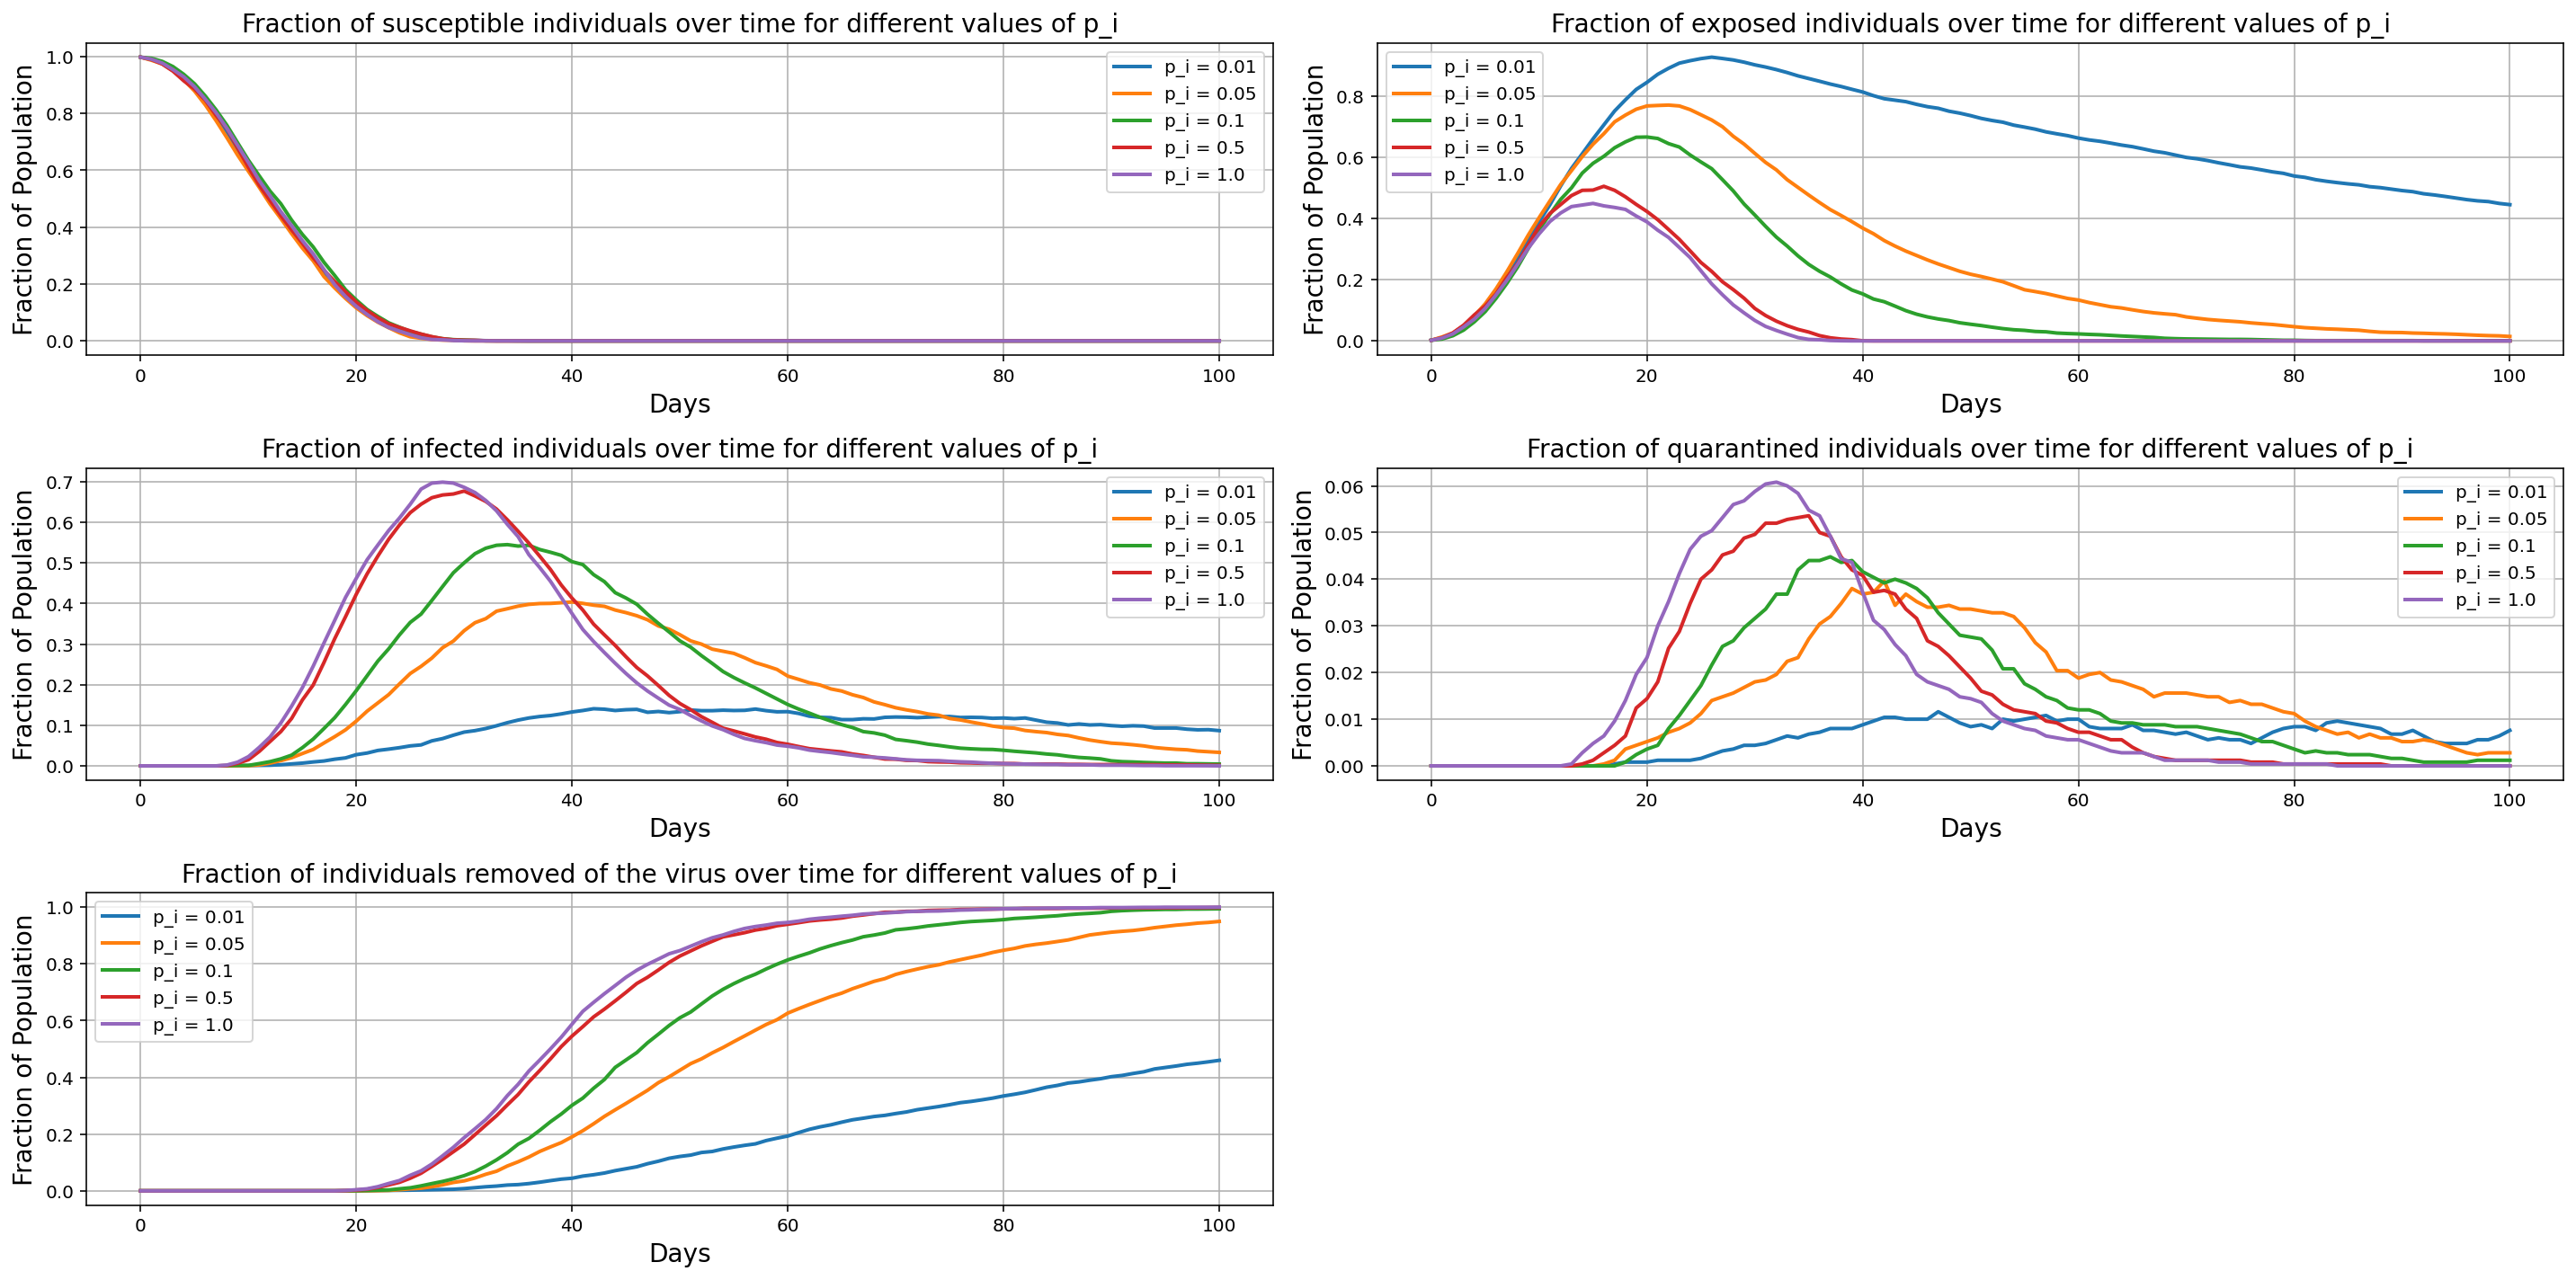

In [23]:
# Number of individuals over time for different values of p_i
initial_e = 5 # Initial number of exposed individuals

size = 50 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Default probability for susceptible indviduals to become exposed
p_i = VariableWrapper(0.01, 'p_i') # Initial probability for exposed indviduals to show symptoms after incubation period
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = 5 # Default time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = 1 # Default value for population density

inc = np.array([0.04, 0.05, 0.4, 0.5, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
plot_states(grid, p_i, inc, size, days, p_e, p_i.value, p_q, p_r, t_i, t_q, t_r, d)

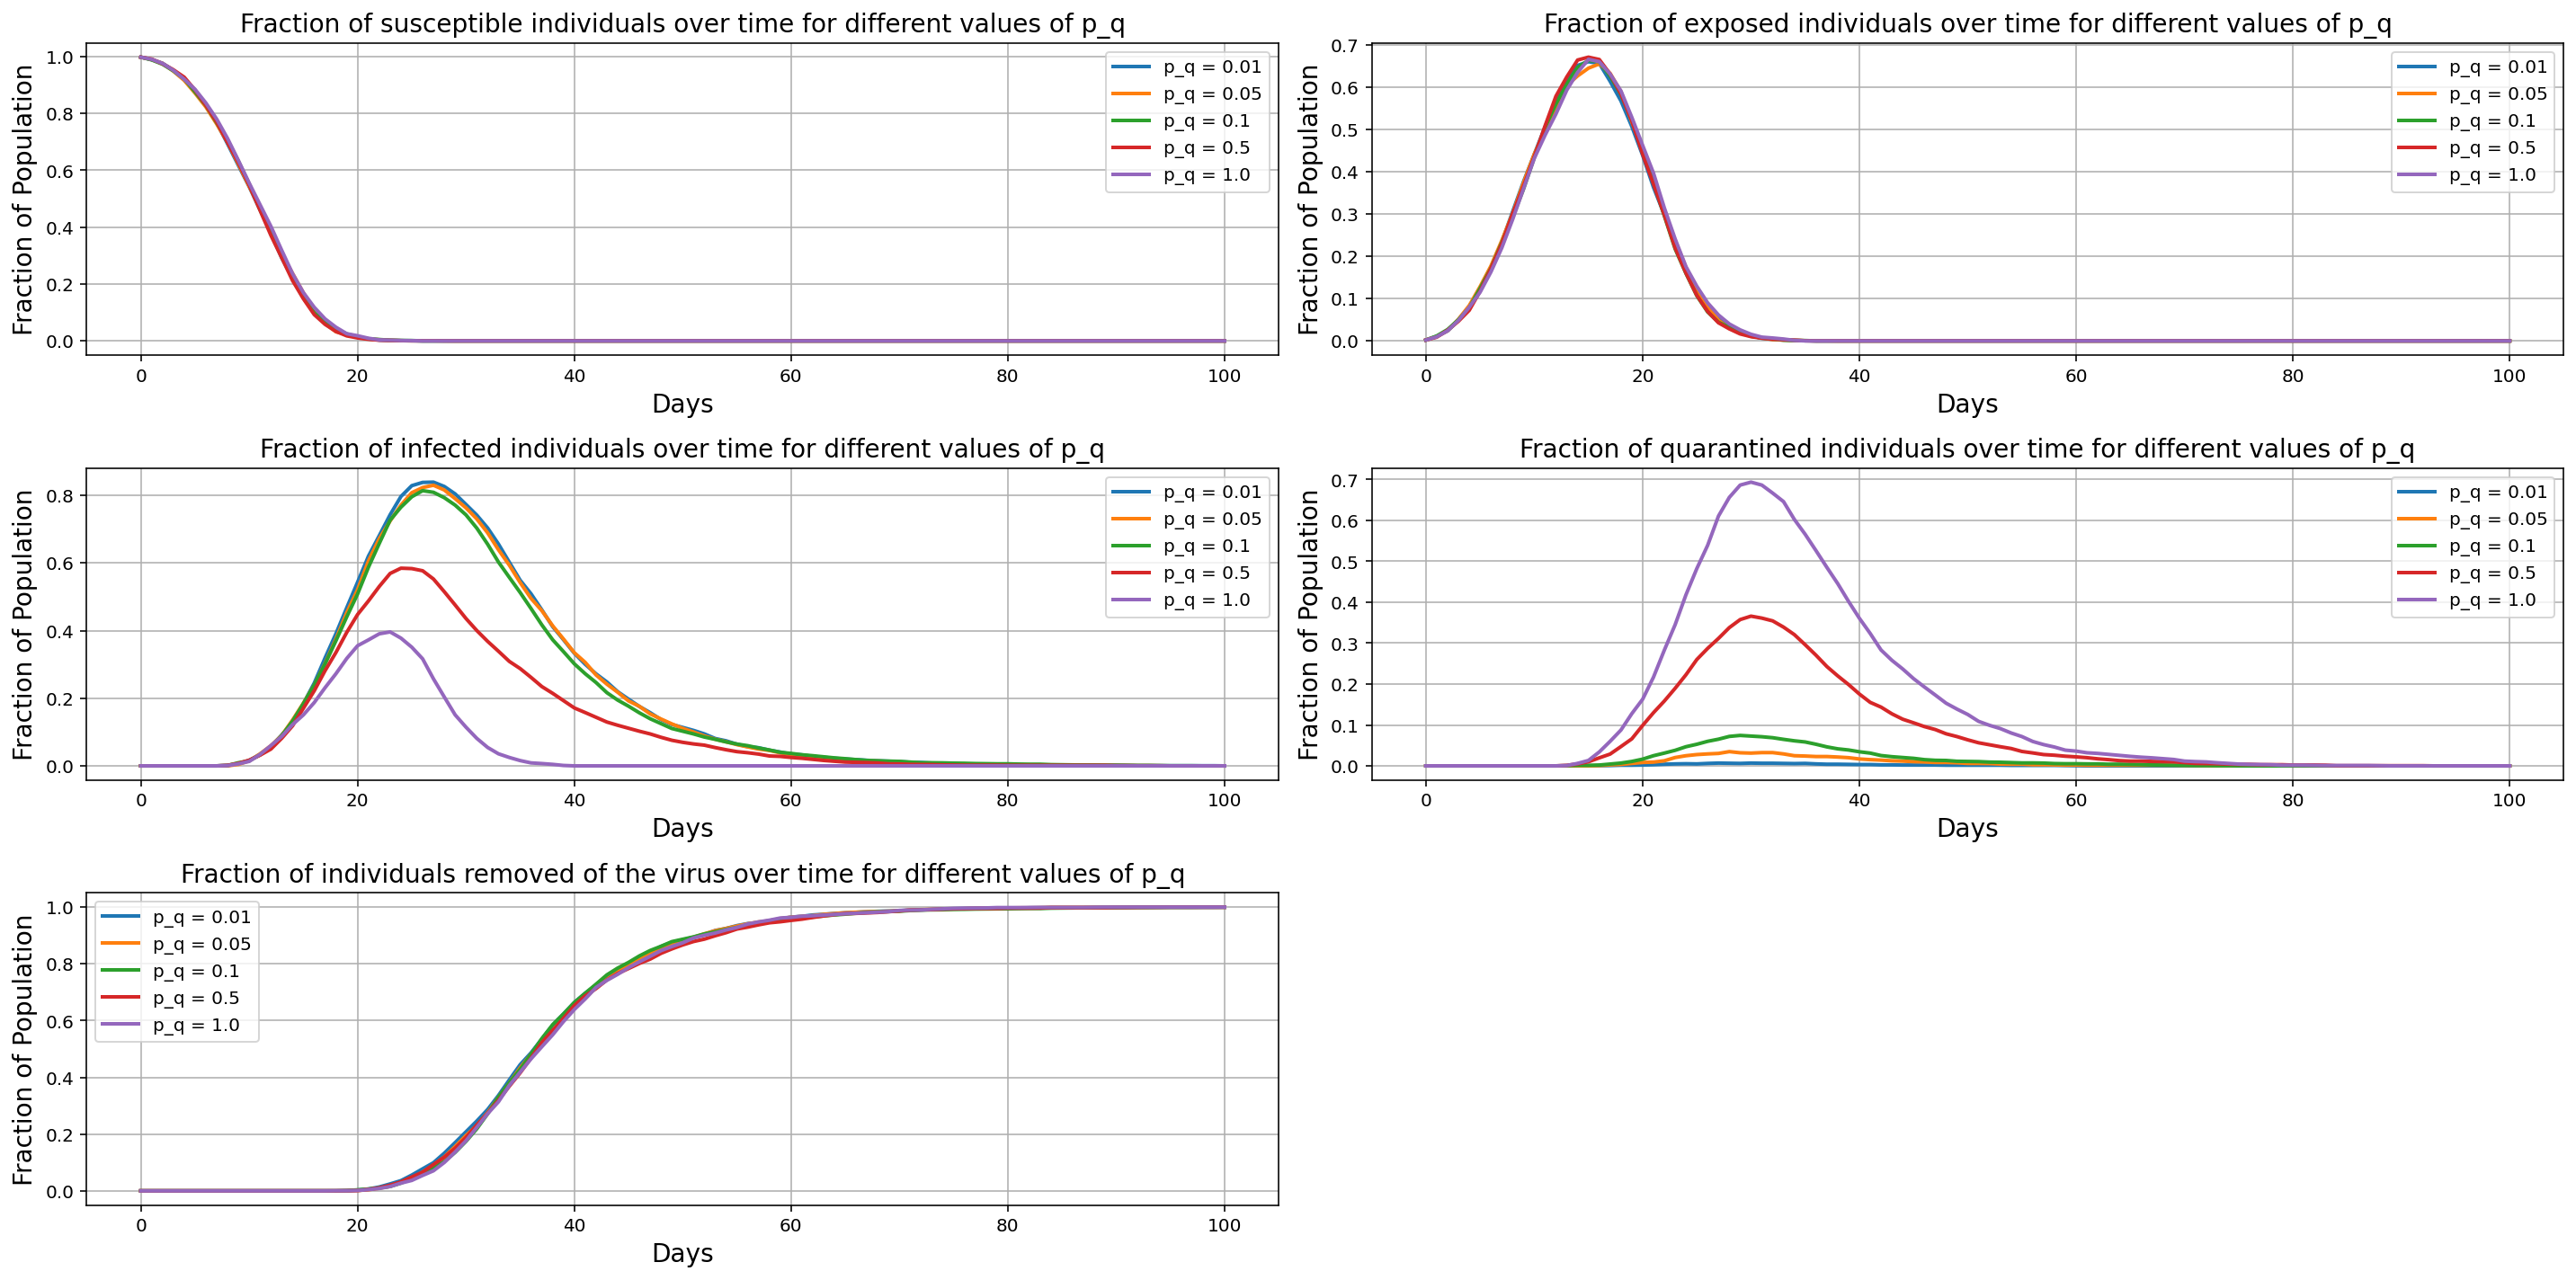

In [10]:
# Number of individuals over time for different values of p_q
initial_e = 5 # Initial number of exposed individuals

size = 50 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Default probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to show symptoms after incubation period
p_q = VariableWrapper(0.01, 'p_q') # Initial probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = 5 # Default time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = 1 # Default value for population density

inc = np.array([0.04, 0.05, 0.4, 0.5, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
plot_states(grid, p_q, inc, size, days, p_e, p_i, p_q.value, p_r, t_i, t_q, t_r, d)

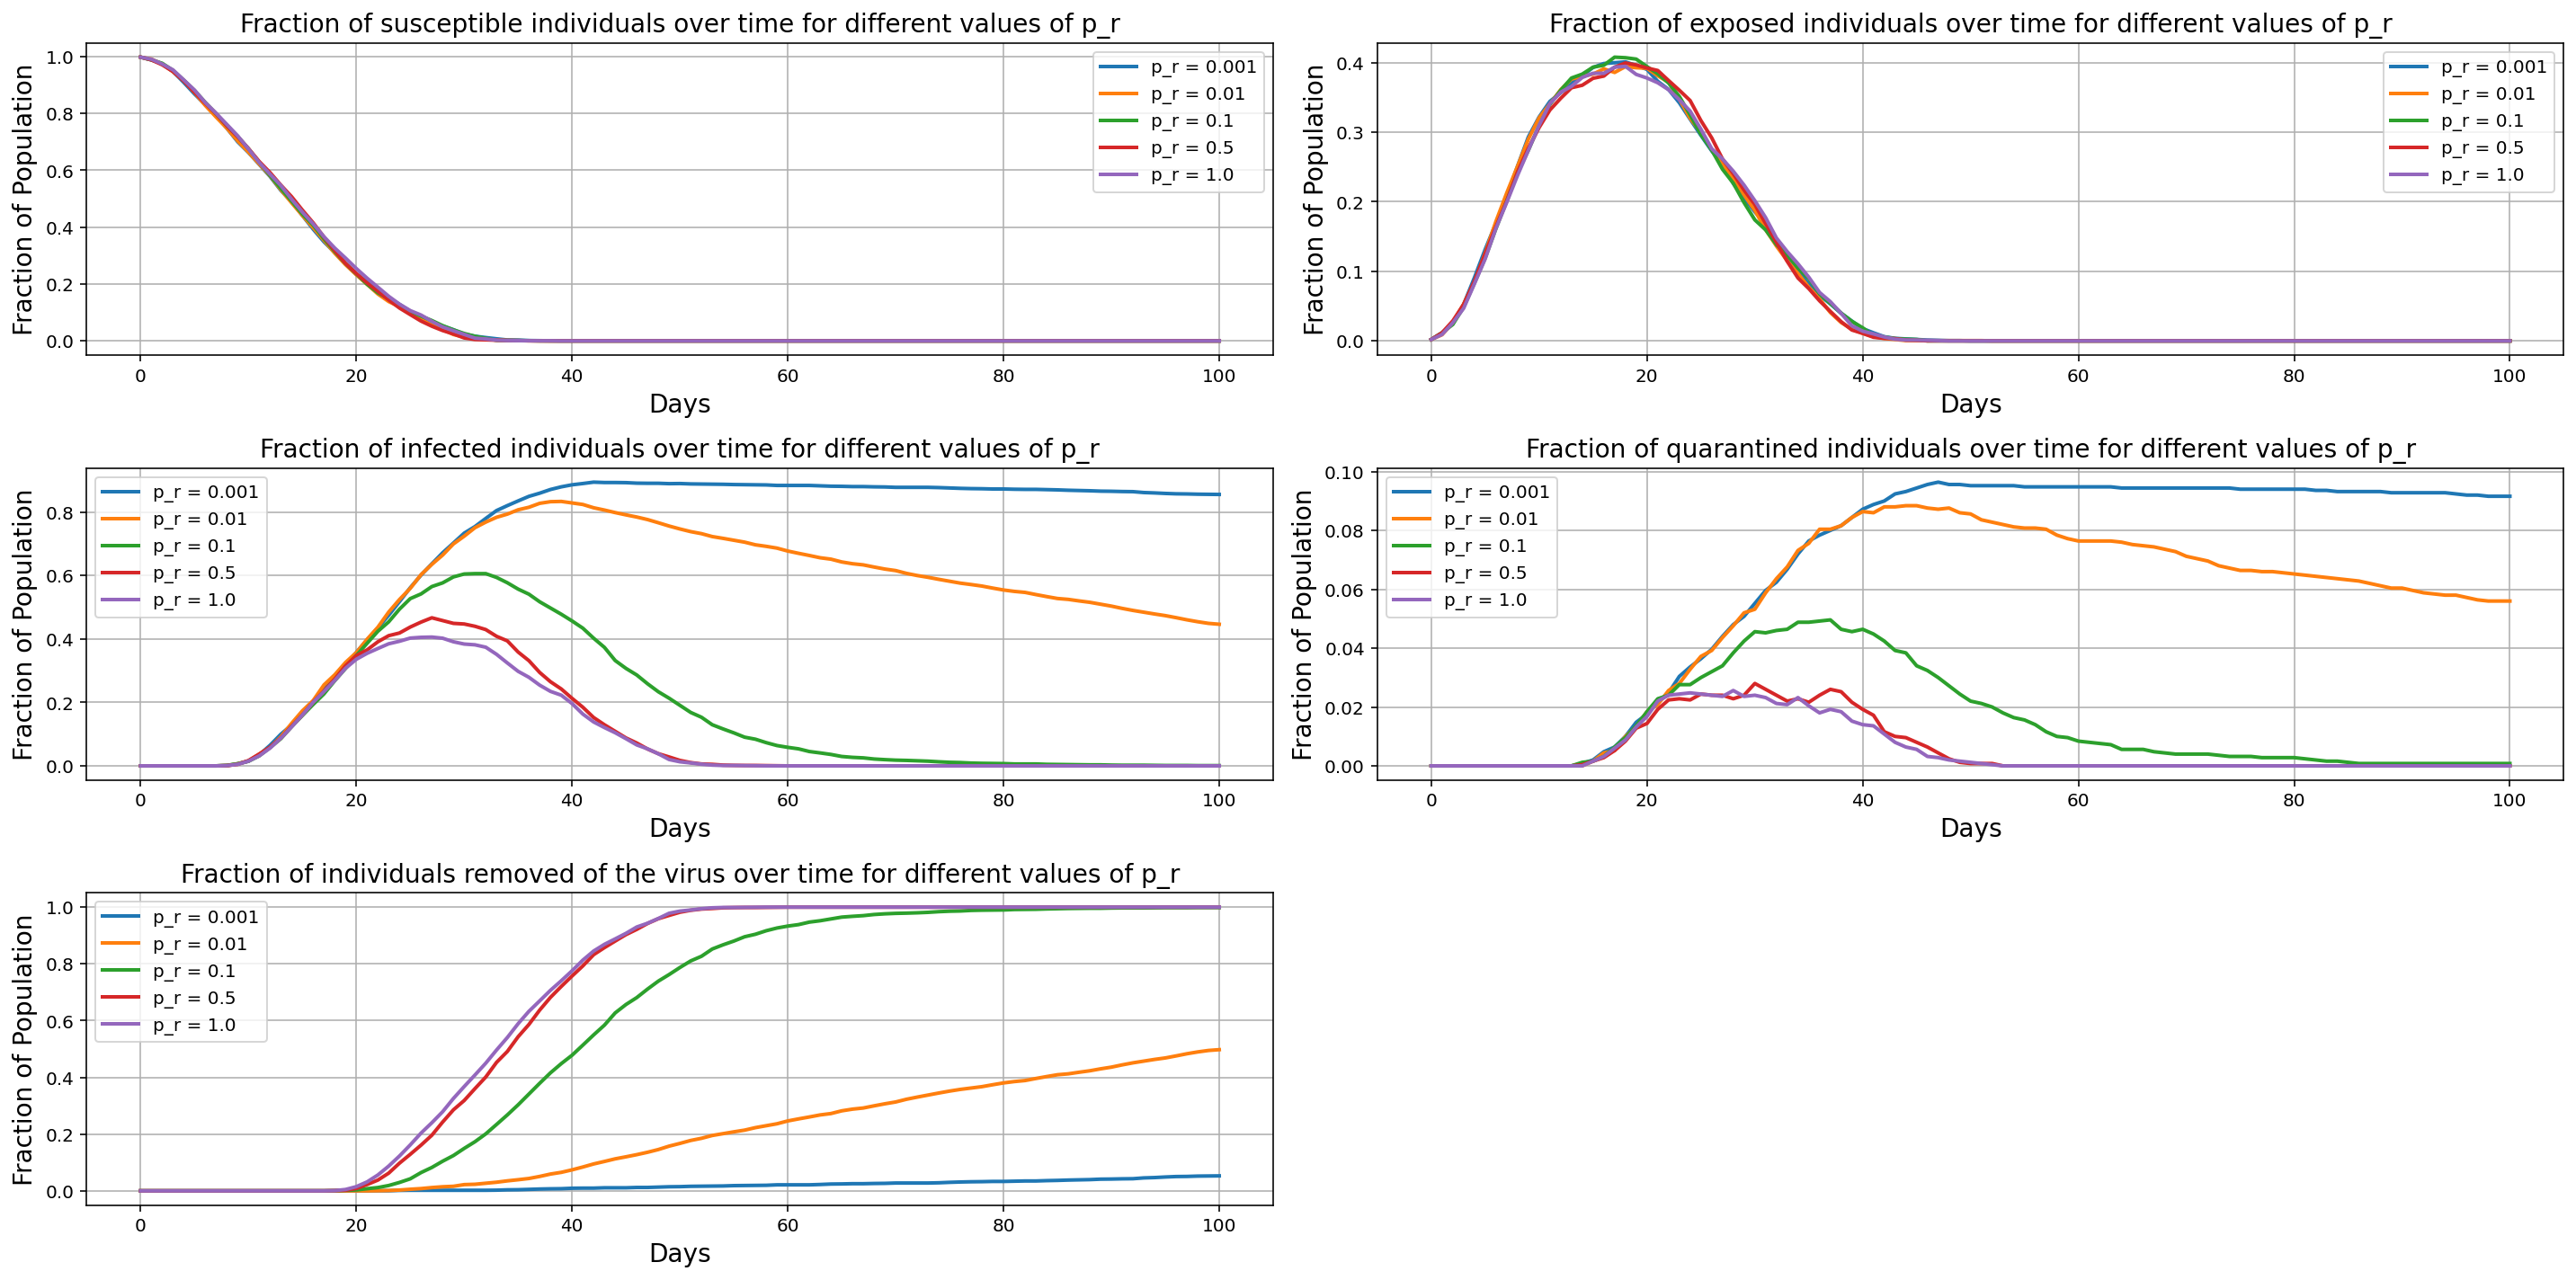

In [24]:
# Number of individuals over time for different values of p_r
initial_e = 5 # Initial number of exposed individuals

size = 50 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Initial probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to show symptoms after incubation period
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = VariableWrapper(0.001, 'p_r') # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = 5 # Default time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = 1 # Default value for population density

inc = np.array([0.009, 0.09, 0.4, 0.5, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
plot_states(grid, p_r, inc, size, days, p_e, p_i, p_q, p_r.value, t_i, t_q, t_r, d)

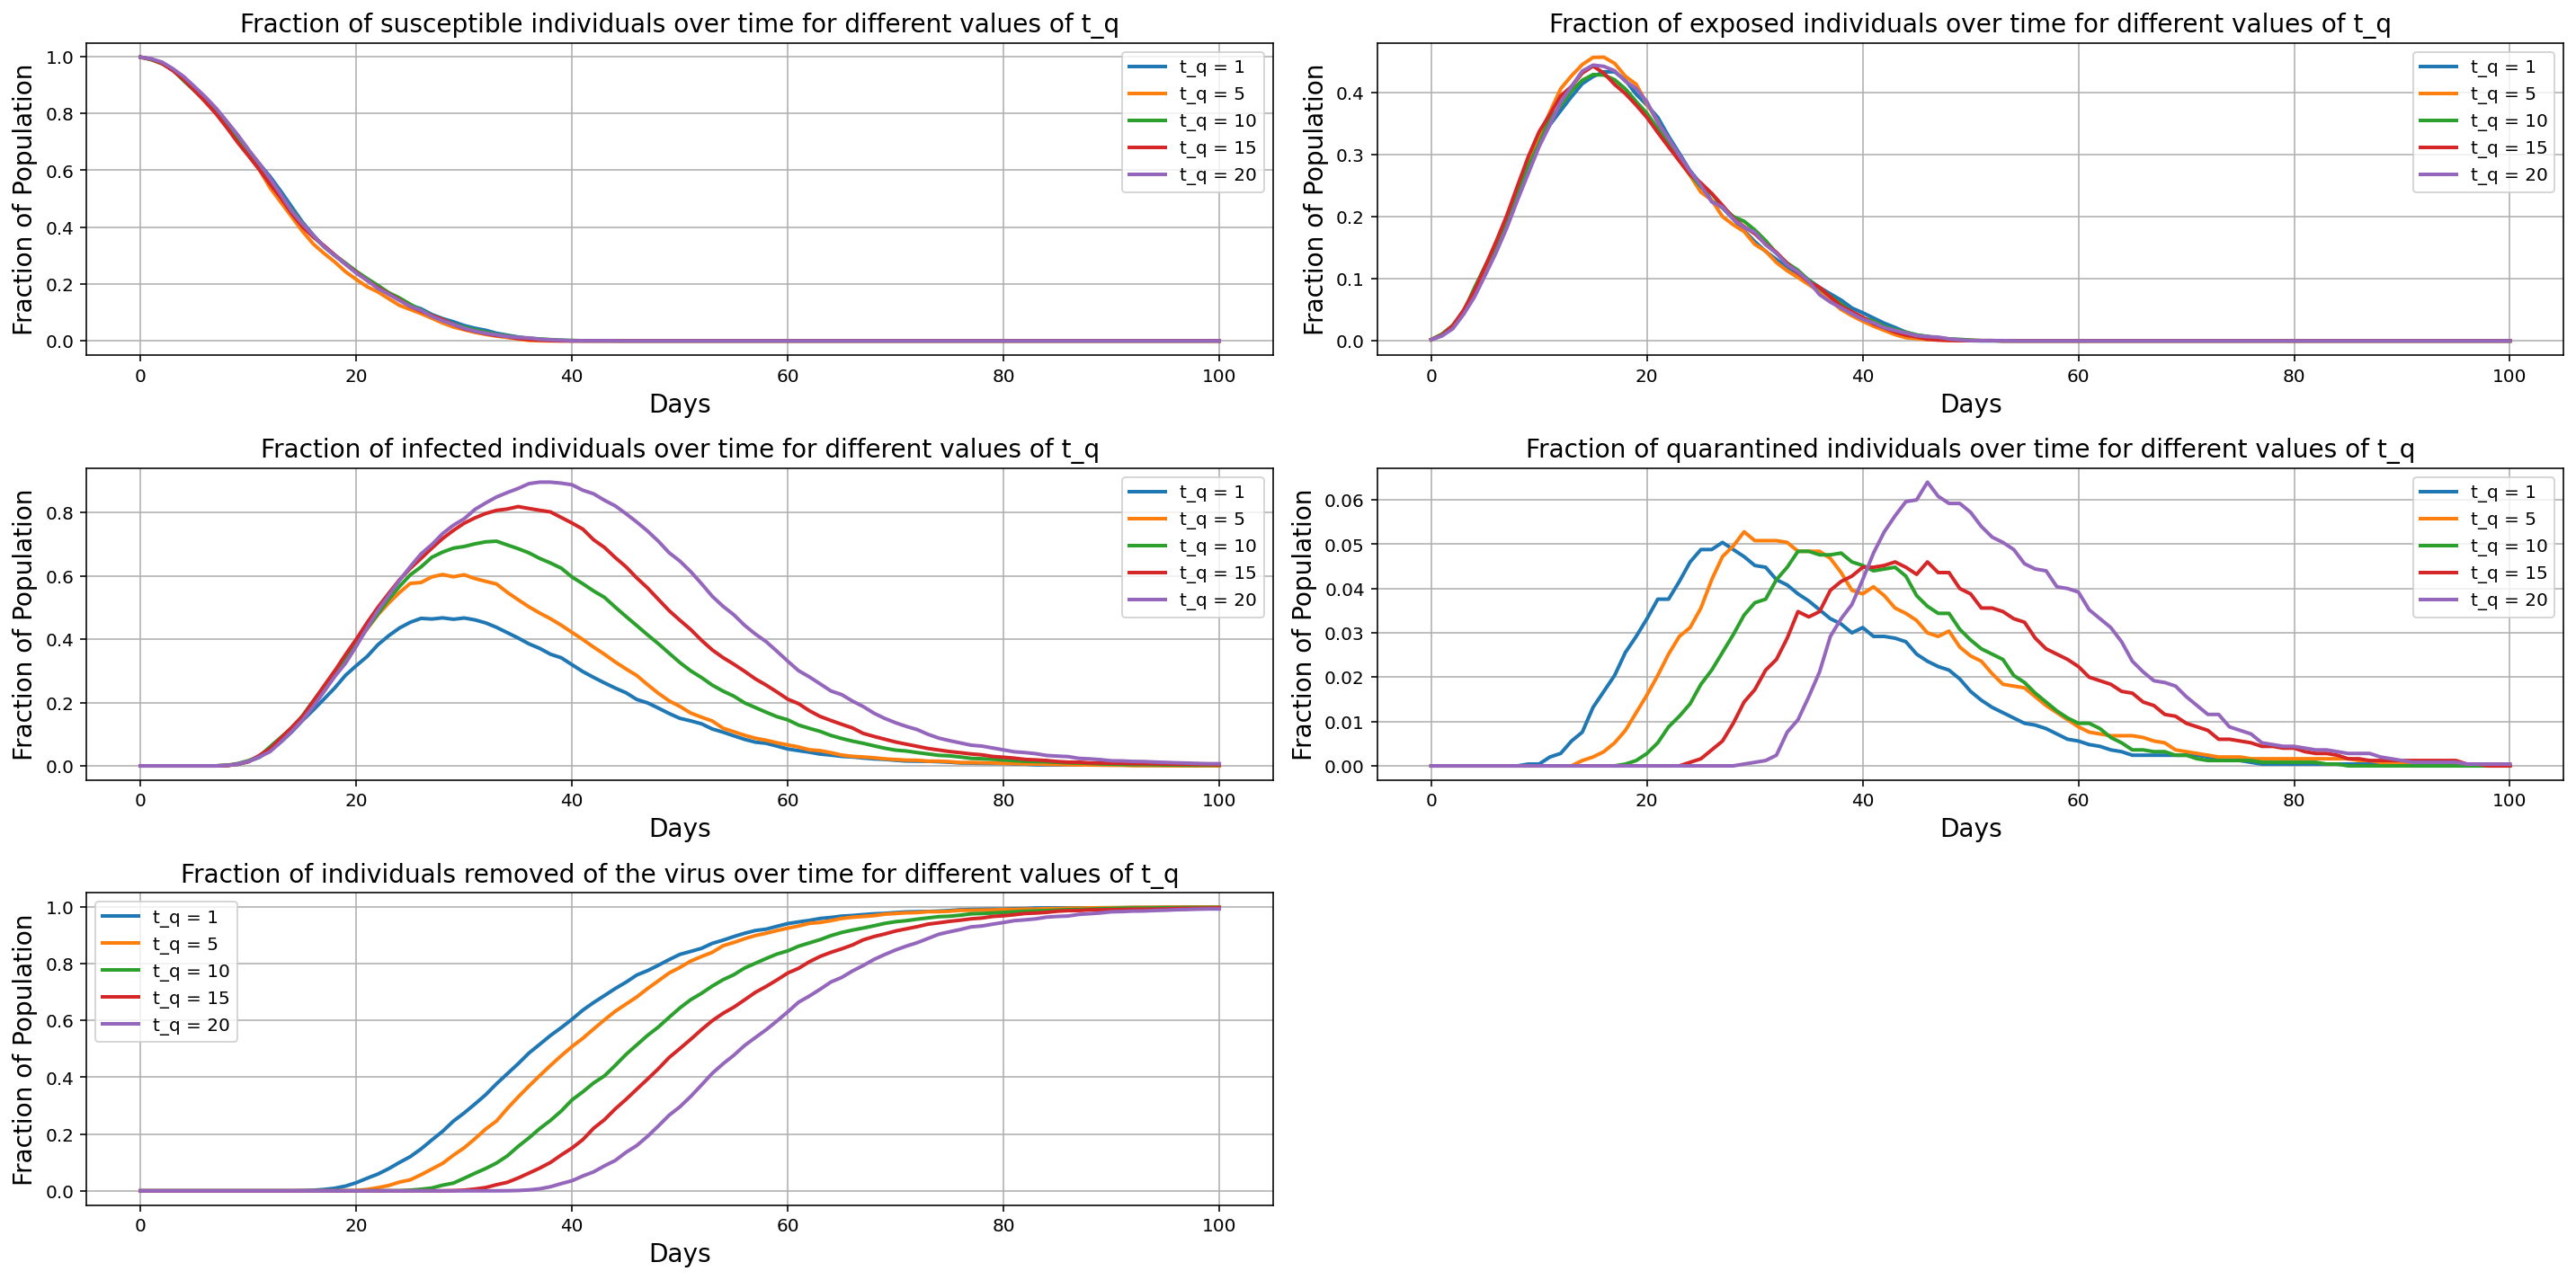

In [12]:
# Number of individuals over time for different values of t_q
initial_e = 5 # Initial number of exposed individuals

size = 50 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Initial probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to show symptoms after incubation period
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = VariableWrapper(1, 't_q') # Initial time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = 1 # Default value for population density

inc = np.array([4, 5, 5, 5, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
plot_states(grid, t_q, inc, size, days, p_e, p_i, p_q, p_r, t_i, t_q.value, t_r, d)

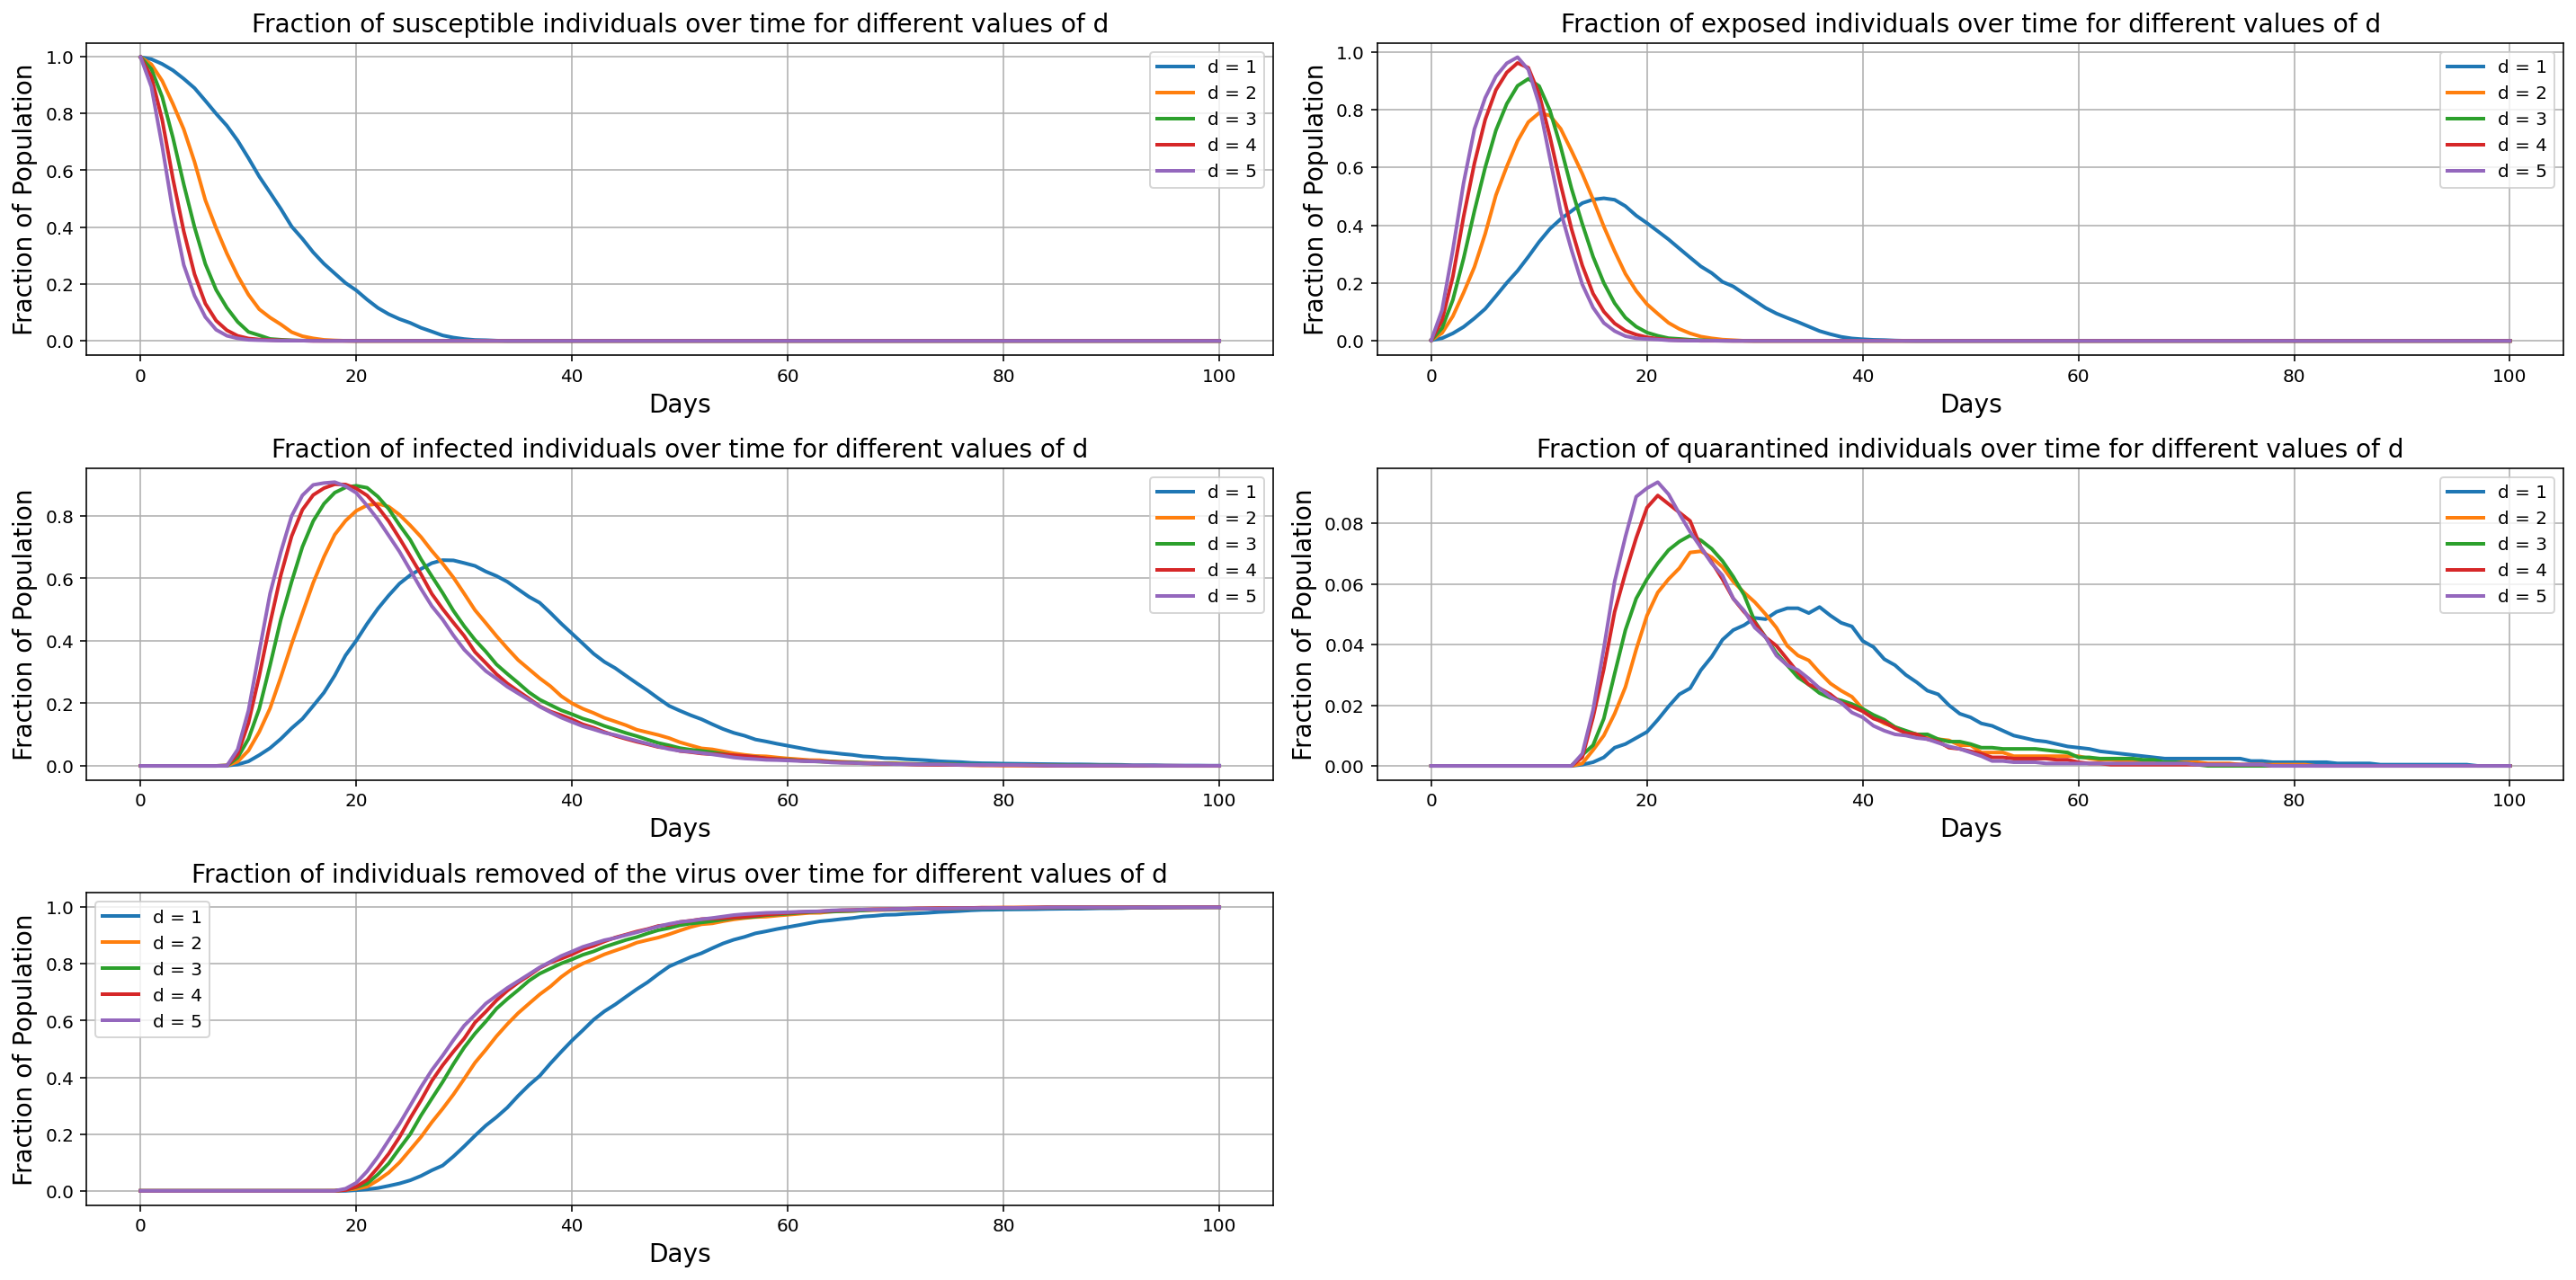

In [13]:
# Number of individuals over time for different values of t_q
initial_e = 5 # Initial number of exposed individuals

size = 50 # Size of grid
days = 100 # Days of simulation

p_e = 0.5 # Initial probability for susceptible indviduals to become exposed
p_i = 0.5 # Default probability for exposed indviduals to show symptoms after incubation period
p_q = 0.1 # Default probability for infected indviduals to become quarantined
p_r = 0.1 # Default probability for indviduals to become removed of the virus

t_i = 8 # Default time delay for for exposed indviduals to become infected
t_q = 5 # Initial time delay for for ifected indviduals to become quarantined
t_r = 5 # Default time delay for for indviduals to become removed of the virus

d = VariableWrapper(1, 'd') # Default value for population density

inc = np.array([1, 1, 1, 1, 0]) # Increment

# Grid initialisation
grid = initialise_grid(size, initial_e)

# Plotting
plot_states(grid, d, inc, size, days, p_e, p_i, p_q, p_r, t_i, t_q, t_r, d.value)

In [0]:
### LOG ###

# 26/02/2024 - 18:23 - Finished base code without incubation or infectious times - Billy

# 27/02/2024 - 09:11 - Added in count_states(x) to help us count at each stage the number in each state, with aims to a function to plot simulations over a series of timesteps - Laura :)

# 29/03/2024 - 03:02 - Finished code to include latent and incubation periods. Updated variable and function names. Updated colourmap function to work with the revamped state system. Note: I think the count_states function no longer works properly with the new system, sorry :( I have an idea to fix it though - Billy

# 29/03/2024 - 15:37 - Fixed some logic mistakes. Fixed the count_states function. Added more comments - Billy

# 01/03/2024 - 15:22 - Updated state system removing the latent peiod - Billy

# 04/03/2024 - 00:59 - Idk, I did the parameter thing earlier but forgot to write a log and now I've done the state population count thing and graph thing, also tried to make things look more presentable - Billy

# 04/03/2024 - 17:43 - Instead of plotting all the probabilities from 0.1 to 1 in steps of 0.1 for SEIQR, I've coded the graph for one value of each probability (the values chosen were the values defined at the start). The main analysis graphs will be showing a range of probabilities on the same graph (like in the paper) but these initial graphs are quite nice in showing how S E I Q and R relate to each other - Ellie

# 08/03/2024 - 03:00 - Changed incubation time to 8 days. Made graphs to show the fraction of a specific population for different values of p_e. I don't think we need a separate graph for each variable showing the default state; they all showed the same thing as the first graph which already has the initial default values. Cleaned up the code. Updated and made new functions. - Billy

# 08/03/2024 - 03:56 - Tidied up the code and made another cool function for graphs. Still need to add comments. Someone might wanna fiddle with the scaling of the axes to make the graphs more presentable - Billy